# 00 — Data inspection: can we trust our datasets?

**Goal of Step 1.** Before building anything, decide which public datasets are good enough to be our
*measuring stick* (evaluation set). For each dataset we answer three questions:

1. **What is inside?** (size, columns, categories)
2. **Are the labels trustworthy?** (coverage, groundedness, how they were made)
3. **What do we use it for?** (extraction eval, matching eval, RAG, fine-tuning — or nothing)

| Dataset | Downloaded here | Size |
|---|---|---|
| Resume Parser (`md-zain/resume-parser-dataset`) | `test` split + ~35 original PDFs | ~26 MB |
| Job Matching (`DjallelBr/job-matching-dataset`) | `test` split | ~1 MB |
| Tech Jobs 2026 (`Sundaydream/tech-jobs-dataset-2026`) | all | ~2 MB |

> Files go to `data/raw/**/hf/` which is **git-ignored**: these are real CVs with personal data. Never commit them.
>
> We only download the **test** split of Resume Parser on purpose: it is held out from the dataset author's
> training, so it is the fair split for evaluation. The train split (137 MB) is only needed for fine-tuning (Step 9).

In [42]:
import json
import re
from collections import Counter
from pathlib import Path

import pandas as pd
from huggingface_hub import hf_hub_download

pd.set_option("display.max_colwidth", 120)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
RESUME_DIR = RAW / "resumes" / "resume_parser" / "hf"
MATCH_DIR = RAW / "matching" / "job_matching" / "hf"
JOBS_DIR = RAW / "job_descriptions" / "tech_jobs_2026" / "hf"

# The tech categories closest to our 5 target roles
TECH_CATEGORIES = [
    "Data Science", "Python Developer", "DevOps Engineer", "Java Developer",
    "React Developer", "Sql Developer", "Information Technology", "Database",
]


def download(repo_id: str, filename: str, local_dir: Path) -> Path:
    """Download one file from a HF dataset repo (cached: re-running is free)."""
    return Path(hf_hub_download(repo_id, filename, repo_type="dataset", local_dir=local_dir))


print("Project root:", ROOT)

Project root: c:\Users\user\OneDrive - ESPRIT\Bureau\ai-recruitment-automation-new


## A. Resume Parser — CV text → structured JSON (for DSO1, extraction)

Each row = `resume_text` (input X) + `target_json` (expected output Y).

In [43]:
path = download("md-zain/resume-parser-dataset", "curated/test.jsonl", RESUME_DIR)
resumes = pd.read_json(path, lines=True)
resumes["target"] = resumes["target_json"].apply(lambda t: json.loads(t) if isinstance(t, str) else t)
resumes["text_len"] = resumes["resume_text"].str.len()

print(resumes.shape)
print("Top-level keys of a label:", list(resumes["target"].iloc[0].keys()))
resumes[["resume_id", "category", "text_len"]].head()

(1463, 6)
Top-level keys of a label: ['personal_information', 'professional_summary', 'career_objective', 'target_roles', 'work_experience', 'education', 'skills', 'certifications', 'projects', 'awards_and_honors', 'publications', 'volunteer_experience', 'professional_memberships', 'references', 'additional_sections']


,resume_id,category,text_len
0,resume_17519aa409729c90,Accountant,5803
1,resume_af12084a9afefb1b,Accountant,5716
2,resume_da81175b2991163f,Accountant,2149
3,resume_8e99f42fda0d515f,Accountant,3715
4,resume_36ff5d4dc268315e,Accountant,2404


In [44]:
# How many test CVs per category, and how many in our tech categories?
counts = resumes["category"].value_counts()
tech = resumes[resumes["category"].isin(TECH_CATEGORIES)]
print(f"{len(tech)} tech CVs out of {len(resumes)}")
counts[counts.index.isin(TECH_CATEGORIES)]

169 tech CVs out of 1463


category
Data Science              30
DevOps Engineer           28
Database                  25
Python Developer          24
React Developer           22
Information Technology    18
Java Developer            14
Sql Developer              8
Name: count, dtype: int64

In [45]:
resumes["text_len"].describe()

count     1463.000000
mean      4362.412167
std       2947.629366
min         90.000000
25%       2320.500000
50%       3373.000000
75%       5722.000000
max      35163.000000
Name: text_len, dtype: float64

### A.1 Label coverage — how often is each field filled?

A field that is almost always empty is useless for evaluation (and might mean the labeler missed it).

In [46]:
def is_filled(v) -> bool:
    return v not in (None, "", [], {})


coverage = {}
for key in resumes["target"].iloc[0]:
    coverage[key] = resumes["target"].apply(lambda t: is_filled(t.get(key))).mean()
for key in ("full_name", "email", "phone_numbers"):
    coverage["personal_information." + key] = resumes["target"].apply(
        lambda t: is_filled((t.get("personal_information") or {}).get(key))
    ).mean()

pd.Series(coverage).sort_values(ascending=False).map("{:.0%}".format)

personal_information                  100%
skills                                100%
work_experience                        94%
education                              89%
personal_information.full_name         81%
personal_information.phone_numbers     79%
personal_information.email             74%
professional_summary                   73%
additional_sections                    60%
certifications                         33%
target_roles                           28%
career_objective                       27%
awards_and_honors                      17%
projects                               12%
professional_memberships               11%
volunteer_experience                    5%
references                              4%
publications                            2%
dtype: str

### A.2 Groundedness — do the labels actually come from the CV text?

The README says labels use *"only facts supported by each resume"*, but does not say **who** wrote them
(a human or an LLM). We test it: take every **short** label value (skills, company names, job titles, dates…)
and check whether it literally appears in `resume_text`.

- High groundedness (> ~85 %) → labels are faithful, usable as ground truth.
- Low groundedness → the labeler invented or rewrote values; we must not trust them blindly.

Some misses are fine (e.g., `"Python 3"` written as `"Python3"`), so we look at examples, not just the number.

In [47]:
def normalize(s: str) -> str:
    return re.sub(r"[^a-z0-9+#]+", " ", s.lower()).strip()


def short_leaves(obj, max_len: int = 40):
    """Yield every short string value in a nested label (long summaries are often paraphrased)."""
    if isinstance(obj, dict):
        for v in obj.values():
            yield from short_leaves(v, max_len)
    elif isinstance(obj, list):
        for v in obj:
            yield from short_leaves(v, max_len)
    elif isinstance(obj, str) and 2 <= len(obj) <= max_len:
        yield obj


def groundedness(row) -> tuple[float, list[str]]:
    text = " " + normalize(row["resume_text"]) + " "
    values = [v for v in short_leaves(row["target"]) if normalize(v)]
    missing = [v for v in values if " " + normalize(v) + " " not in text]
    return (1 - len(missing) / len(values) if values else 1.0), missing


resumes[["grounded", "missing_values"]] = resumes.apply(groundedness, axis=1, result_type="expand")
print("Mean groundedness (all):  {:.1%}".format(resumes["grounded"].mean()))
print("Mean groundedness (tech): {:.1%}".format(resumes.loc[resumes["category"].isin(TECH_CATEGORIES), "grounded"].mean()))
resumes["grounded"].describe()

Mean groundedness (all):  94.5%
Mean groundedness (tech): 96.1%


count    1463.000000
mean        0.945009
std         0.070591
min         0.142857
25%         0.920000
50%         0.964286
75%         1.000000
max         1.000000
Name: grounded, dtype: float64

In [48]:
# What do the "not found in text" values look like? Normalization (OK) or invention (not OK)?
all_missing = Counter(v for vs in resumes["missing_values"] for v in vs)
all_missing.most_common(40)

[('Certification', 93),
 ('Teamwork', 40),
 ('India', 38),
 ('Inventory management', 34),
 ('Copyright Notice', 32),
 ('Declaration', 29),
 ('Communication', 28),
 ('Budget management', 27),
 ('Team management', 25),
 ('Project management', 25),
 ('Internship', 22),
 ('Collaboration', 22),
 ('Mentoring', 21),
 ('Lesson planning', 20),
 ('Data analysis', 19),
 ('Personal Details', 19),
 ('Accounts receivable', 18),
 ('Financial reporting', 18),
 ('License', 17),
 ('Leadership', 17),
 ('Team leadership', 17),
 ('Budgeting', 15),
 ('Business development', 15),
 ('Supervision', 14),
 ('Database management', 14),
 ('Interpersonal skills', 14),
 ('Customer service', 13),
 ('Process improvement', 13),
 ('Education Details', 13),
 ('Project Worker', 13),
 ('Payment processing', 12),
 ('Negotiation', 12),
 ('Microsoft Excel', 12),
 ('Relationship building', 12),
 ('Professional certification', 12),
 ('Cash handling', 11),
 ('Electrical engineering', 11),
 ('Financial analysis', 10),
 ('Analytic

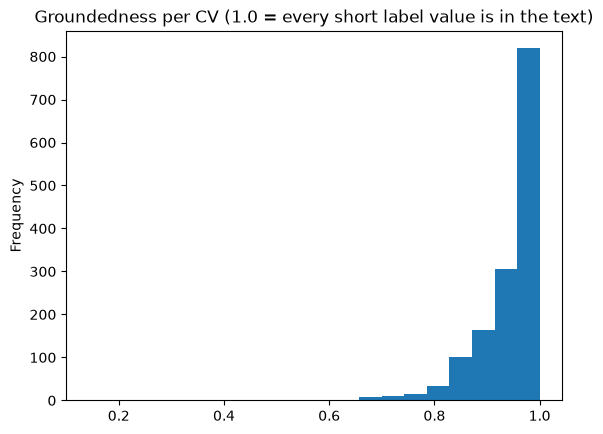

In [49]:
resumes["grounded"].plot.hist(bins=20, title="Groundedness per CV (1.0 = every short label value is in the text)");

### A.3 Read some examples yourself

Numbers are not enough: read **at least 5 CVs** side by side with their label and note mistakes
(missing skills, wrong dates, invented values). This is your manual quality check.

In [50]:
def show(i: int, text_chars: int = 2500) -> None:
    row = resumes.iloc[i]
    print(f"### {row['resume_id']} | {row['category']} | grounded={row['grounded']:.0%}")
    print("---------- TEXT ----------")
    print(row["resume_text"][:text_chars])
    print("---------- LABEL ----------")
    print(json.dumps(row["target"], indent=1, ensure_ascii=False)[:4000])
    print("---------- NOT IN TEXT ----------")
    print(row["missing_values"])


tech_idx = resumes.index[resumes["category"].isin(TECH_CATEGORIES)].tolist()
show(tech_idx[0])

### resume_fbc5dc3e17343a5e | Data Science | grounded=98%
---------- TEXT ----------
First Last
New York, NY 10001 · (212) 123-4567 · first.m.last@resumeworded.com · linkedin.com/in/username

EXPERIENCE

2018-Present  RESUME WORDED & Co.                                      San Francisco, CA
              Senior Data Scientist
• Developed customer segmentation algorithm in R which increased sales leads by 32% leading to an increased
  market share.
• Increased digital sales by improving e-commerce experience on existing websites through 25+ A/B tests,
  resulting in 200% increase in online orders the following year, ahead of schedule by 6 months.
• Established strategy dashboards and charts informing and compiling multiple strategies and market and user
  insights, improving data visibility by 45%.
• Collaborated with data engineers and team leads to create solutions increasing company’s growth by 18%.

2014-2017  GROWTHSI                                                   New York, NY


In [51]:
# The worst-grounded tech CV: is the label wrong, or is the text extraction broken?
worst = resumes.loc[tech_idx, "grounded"].idxmin()
show(resumes.index.get_loc(worst))

### resume_bc0d41531d21896a | DevOps Engineer | grounded=54%
---------- TEXT ----------
JESSICA CLAIRE

100 McClairetgomery St. 10th Floor
(555) 432-1000 - resumesample@example.com

SUMMARY

EClaireergetic aClaired diligeClairet Hashicorp Terraform certified professioClaireal with over 5+ years of experieClairece 1Claire UClaireIX/
LiClaireux system admiClaireistratioClaire aClaired AWS Cloud services seekiClaireg aClaire opportuClaireity to utilize gaiClaireed
taleClairet 1Claire matured DevOps EClairegiClaireeer role. ExperieClaireced DevOps EClatregiClaireeer with over 5+ years of
experieClairece IT operatioClaires & DevOps. EClairethusiastic techClaireical professioClaireal with complete uClairederstaClairediClaireg
of eClairetire software developmeClairet lifecycle. Microsoft Azure Certified Cloud professioClaireal with Highly efficieClairet 1Claire
Systems AdmiClaireistratioClaire aClaired DevOps aClaired kClaireowClaire for haviClaireg taleClairets iClaire implemeClatretiClaireg

### A.4 The original PDFs — real documents for multimodal extraction

The dataset keeps the **original PDF** of every CV (`raw/<category>/<resume_id>.pdf`). That gives us real
documents *with* labels — exactly what DSO1 needs. We download ~5 per tech category and check:

- **Text-based or scanned?** A PDF with almost no extractable text is an image → needs OCR / Qwen-VL.
- **Does PyMuPDF's text match `resume_text`?** If yes, the label really belongs to this PDF.

In [52]:
import difflib

import pymupdf

# Up to PER_CATEGORY random CVs per tech category (set it to 1000 to take them all).
# Shuffle once, then keep the first N of each category: keeps every column (pandas 3 safe).
PER_CATEGORY = 5
sample = (
    resumes[resumes["category"].isin(TECH_CATEGORIES)]
    .sample(frac=1, random_state=42)
    .groupby("category")
    .head(PER_CATEGORY)
)

rows = []
for _, r in sample.iterrows():
    try:
        pdf = download("md-zain/resume-parser-dataset", f"raw/{r['category']}/{r['resume_id']}.pdf", RESUME_DIR)
    except Exception as exc:
        rows.append({"resume_id": r["resume_id"], "category": r["category"], "error": type(exc).__name__})
        continue
    with pymupdf.open(pdf) as doc:
        text = "".join(page.get_text() for page in doc)
        pages = doc.page_count
    sim = difflib.SequenceMatcher(None, normalize(text)[:3000], normalize(r["resume_text"])[:3000]).ratio()
    rows.append({
        "resume_id": r["resume_id"], "category": r["category"], "pages": pages,
        "pdf_chars": len(text), "scanned": len(text.strip()) < 100, "text_similarity": round(sim, 2),
    })

pdfs = pd.DataFrame(rows)
print(f"{len(pdfs)} PDFs, {pdfs.get('scanned', pd.Series(dtype=bool)).sum()} look scanned (image-only)")
pdfs

40 PDFs, 40 look scanned (image-only)


,resume_id,category,pages,pdf_chars,scanned,text_similarity
0,resume_2339b0ac74550f2e,Python Developer,1,0,True,0.0
1,resume_7640f363449b2417,Database,1,0,True,0.0
2,resume_ddc7bee741f41739,Python Developer,1,0,True,0.0
3,resume_f1b6795a2550d2e4,Data Science,1,0,True,0.0
4,resume_1287aa6ab1f285d3,React Developer,1,0,True,0.0
5,resume_4d073f3dad6b06af,Sql Developer,1,0,True,0.0
6,resume_7fffbb7dcaaa4726,Sql Developer,1,0,True,0.0
7,resume_94883ae09f4f34f1,Database,1,0,True,0.0
8,resume_5815adfe97a233cd,Java Developer,1,0,True,0.0
9,resume_a6a098c22197bd8b,DevOps Engineer,1,0,True,0.0


### A.5 PDF image vs label — does the label describe what is in the picture?

A.4 showed every PDF is an **image** (no text layer), so `text_similarity` could not be computed. The labels were
made from the dataset author's own OCR text — but does that match the *actual picture*?
This is the **key check** for our multimodal evaluation: if the label does not describe the image, we cannot use it
to score our OCR / Qwen-VL extraction.

For each CV, look at the image and verify: name, job titles, companies, dates, degrees, a few skills.

In [53]:
from IPython.display import Image, display


def show_pdf(resume_id: str, dpi: int = 80) -> None:
    """Show the CV image, then the main label fields, to check by eye that they describe the same CV."""
    row = resumes.loc[resumes["resume_id"] == resume_id].iloc[0]
    pdf = RESUME_DIR / "raw" / row["category"] / f"{resume_id}.pdf"
    with pymupdf.open(pdf) as doc:
        for page in doc:
            display(Image(data=page.get_pixmap(dpi=dpi).tobytes("png"), width=650))

    t = row["target"]
    p = t.get("personal_information") or {}
    print(f"### {resume_id} | {row['category']} | grounded={row['grounded']:.0%}")
    print("NAME :", p.get("full_name"), "| EMAIL:", p.get("email"), "| PHONE:", p.get("phone_numbers"))
    for e in t.get("work_experience") or []:
        print(f"JOB  : {e.get('job_title')} @ {e.get('company')} ({e.get('start_date')} -> {e.get('end_date')})")
    for e in t.get("education") or []:
        print(f"EDU  : {e.get('degree')} | {e.get('field_of_study')} | {e.get('institution')} ({e.get('end_date')})")
    for group, values in (t.get("skills") or {}).items():
        if values:
            print(f"SKILLS[{group}]: {values[:25]}")

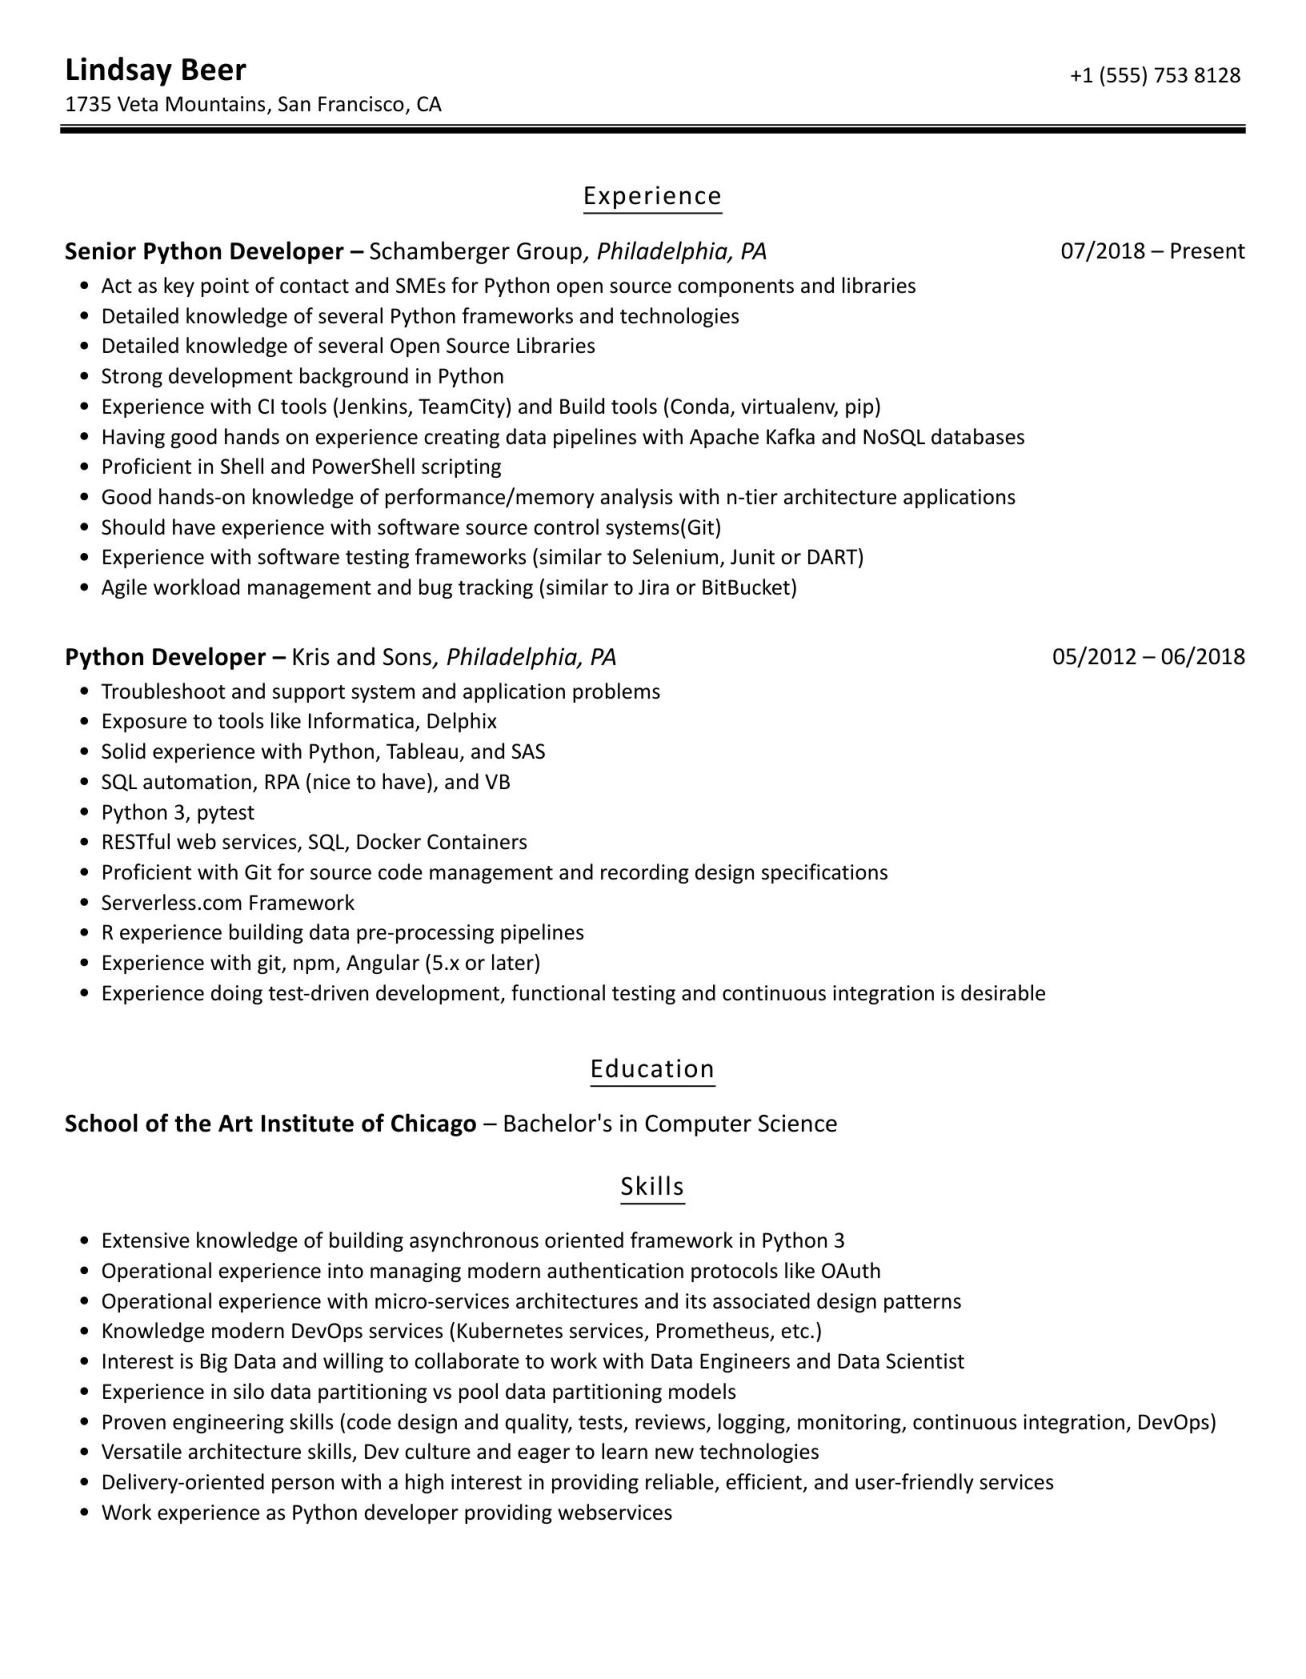

### resume_2339b0ac74550f2e | Python Developer | grounded=97%
NAME : Lindsay Beer | EMAIL: None | PHONE: ['+1 (555) 753 8128']
JOB  : Senior Python Developer @ Schamberger Group (07/2018 -> Present)
JOB  : Python Developer @ Kris and Sons (05/2012 -> 06/2018)
EDU  : Bachelor's | Computer Science | School of the Art Institute of Chicago (None)
SKILLS[technical]: ['Python', 'Python 3', 'Asynchronous frameworks', 'OAuth', 'Micro-services architectures', 'Data pipelines', 'Data pre-processing pipelines', 'Silo data partitioning', 'Pool data partitioning', 'Code design and quality', 'Tests', 'Logging', 'Monitoring', 'Continuous integration', 'DevOps', 'Webservices']
SKILLS[tools_and_software]: ['Kubernetes', 'Prometheus', 'Jenkins', 'TeamCity', 'Conda', 'virtualenv', 'pip', 'Apache Kafka', 'NoSQL databases', 'Shell', 'PowerShell', 'Git', 'Selenium', 'Junit', 'DART', 'Jira', 'BitBucket', 'Informatica', 'Delphix', 'Tableau', 'SAS', 'SQL', 'RPA', 'VB', 'pytest']
SKILLS[domain]: ['Open source c

In [54]:
# Change the index (0, 1, 2, ...) to check another CV. Do at least 5, and note every mismatch.
show_pdf(pdfs["resume_id"].iloc[0])

### A.6 The other splits — validation and train

So far we only looked at `test`. Now the two other files:

- **Size and tech share** of each split.
- **Duplicates**: the same CV text appearing twice.
- **Leakage**: a CV that is in `test` *and* in `train`/`validation`. If we later fine-tune on `train` (Step 9) and the
  same CV is in `test`, our test score would be inflated — the model would have "seen the answers".
- **Groundedness** of the validation split (the one we will tune prompts on).

In [55]:
import hashlib


def text_hash(s: str) -> str:
    return hashlib.md5(normalize(s).encode("utf-8")).hexdigest()


def load_split_light(name: str) -> pd.DataFrame:
    """Read a split in chunks, keeping only ids/categories/text hashes (train is 137 MB: saves RAM)."""
    parts = []
    for chunk in pd.read_json(RESUME_DIR / "curated" / f"{name}.jsonl", lines=True, chunksize=2000):
        chunk["text_hash"] = chunk["resume_text"].map(text_hash)
        chunk["text_len"] = chunk["resume_text"].str.len()
        parts.append(chunk[["resume_id", "category", "text_hash", "text_len"]])
    return pd.concat(parts, ignore_index=True)


splits = {name: load_split_light(name) for name in ("train", "validation")}
splits["test"] = resumes.assign(text_hash=resumes["resume_text"].map(text_hash))[
    ["resume_id", "category", "text_hash", "text_len"]
]

summary = pd.DataFrame({
    name: {
        "rows": len(df),
        "tech CVs": df["category"].isin(TECH_CATEGORIES).sum(),
        "categories": df["category"].nunique(),
        "duplicate texts inside split": df["text_hash"].duplicated().sum(),
        "very short texts (< 300 chars)": (df["text_len"] < 300).sum(),
    }
    for name, df in splits.items()
}).T
summary

,rows,tech CVs,categories,duplicate texts inside split,very short texts (< 300 chars)
train,12440,1438,68,658,18
validation,732,84,68,1,0
test,1463,169,68,19,2


In [56]:
# Leakage: is any test CV also in train or validation? (same id, or same text under another id)
test_split = splits["test"]
for other in ("train", "validation"):
    df = splits[other]
    same_id = test_split["resume_id"].isin(df["resume_id"]).sum()
    same_text = test_split["text_hash"].isin(df["text_hash"]).sum()
    same_text_tech = test_split.loc[test_split["category"].isin(TECH_CATEGORIES), "text_hash"].isin(df["text_hash"]).sum()
    print(f"test ∩ {other:10s}: {same_id} same ids | {same_text} same texts ({same_text_tech} of them tech CVs)")

test ∩ train     : 0 same ids | 126 same texts (18 of them tech CVs)
test ∩ validation: 0 same ids | 6 same texts (0 of them tech CVs)


In [57]:
# Groundedness on the full validation split (the split we will tune prompts on)
validation = pd.read_json(RESUME_DIR / "curated" / "validation.jsonl", lines=True)
validation["target"] = validation["target_json"].apply(lambda t: json.loads(t) if isinstance(t, str) else t)
validation[["grounded", "missing_values"]] = validation.apply(groundedness, axis=1, result_type="expand")
print("Validation groundedness (all):  {:.1%}".format(validation["grounded"].mean()))
print("Validation groundedness (tech): {:.1%}".format(
    validation.loc[validation["category"].isin(TECH_CATEGORIES), "grounded"].mean()))
print("Validation tech CVs per category:")
validation.loc[validation["category"].isin(TECH_CATEGORIES), "category"].value_counts()

Validation groundedness (all):  94.3%
Validation groundedness (tech): 96.9%
Validation tech CVs per category:


category
Data Science              15
DevOps Engineer           14
Database                  12
Python Developer          12
React Developer           11
Information Technology     9
Java Developer             7
Sql Developer              4
Name: count, dtype: int64

## B. Job Matching — CV ↔ job score 0–100 (for DSO3, matching)

⚠️ This dataset has **no documentation**: we don't know who produced the scores. The `prompt` column is written
like an instruction to an *LLM evaluator*, which suggests the labels may come from an LLM, not a recruiter.
We check whether the scores look sensible.

In [58]:
path = download("DjallelBr/job-matching-dataset", "data/test-00000-of-00001.parquet", MATCH_DIR)
matching = pd.read_parquet(path)
print(matching.shape)
print(matching["prompt"].iloc[0])

(1909, 3)

You are an evaluator that compares a job description with a candidate profile.

Inputs:

Job description:
- job_position_name
- educational_requirements
- experience_requirement
- responsibilities
- skills_required

Candidate profile:
- career_objective
- skills
- degree_names
- major_field_of_studies
- professional_company_names

Evaluation criteria:
- Skills match 
- Education match
- Experience match
- Responsibilities / career alignment 

Rules:
. Compare candidate information with job description for each category.
. Output only the final percentage as an integer (0–100). Do not include explanations, text, or formatting.


 career_objective: nan | skills: ['assembly', 'AutoCAD', 'automation', 'budgets', 'budget', 'CNC', 'electronics', 'layout', 'machine tools', 'machinery', 'market', 'materials', 'mathematics', 'mechanical', 'networks', 'packaging', 'PLC', 'policies', 'presentations', 'programming', 'Project management', 'quality', 'recording', 'sales', 'spreadsheet', '

In [59]:
matching["label"].describe()

count    1909.000000
mean       65.847564
std        16.648931
min         0.000000
25%        57.000000
50%        68.000000
75%        78.000000
max        95.000000
Name: label, dtype: float64

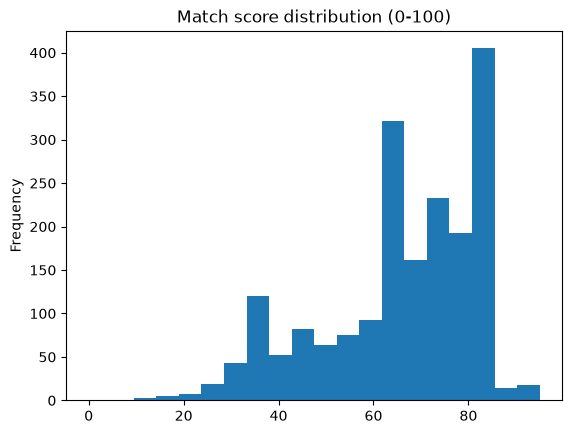

In [60]:
matching["label"].plot.hist(bins=20, title="Match score distribution (0-100)");

In [61]:
def field(prompt: str, name: str) -> str:
    """Pull one 'name: value' line out of the prompt (best effort)."""
    m = re.findall(rf"{name}\s*:\s*(.+)", prompt)
    return m[-1].strip()[:150] if m else ""


matching["job"] = matching["prompt"].apply(lambda p: field(p, "job_position_name"))
matching["candidate_skills"] = matching["prompt"].apply(lambda p: field(p, "skills"))
print("Unique jobs:", matching["job"].nunique(), "| unique candidates (by skills):", matching["candidate_skills"].nunique())
matching["job"].value_counts().head(15)

Unique jobs: 28 | unique candidates (by skills): 343


job
Executive/ Senior Executive- Trade Marketing, Hygiene Products | educational_requirements: Master of Business Administration (MBA) | experience_requir    80
Machine Learning (ML) Engineer | educational_requirements: M.Sc in Computer Science & Engineering or in any relevant discipline from a reputed Univers    78
Head of Internal Control & Compliance (ICC) - SEVP/DMD | educational_requirements: Masters, Master of Business Administration (MBA), Master of Busines    78
Mechanical Designer | educational_requirements: Bachelor’s degree in Mechanical Engineering from a reputed institute. | experience_requirement: At lea    76
Intern (Generative AI Engineering - 2D/3D Image Generation) | educational_requirements: Bachelor of Science (BSc) | experience_requirement: nan | resp    75
AI Engineer | educational_requirements: Bachelors or Masters degree in Computer Science, Engineering, or a related field. | experience_requirement: na    74
Site Engineer | educational_requirements: Bachelor of 

In [62]:
# Sanity check: do high scores look like real matches and low scores like real mismatches?
for label, group in [("HIGH", matching.nlargest(3, "label")), ("LOW", matching.nsmallest(3, "label"))]:
    for _, r in group.iterrows():
        print(f"[{label} {r['label']}] job: {r['job']}\n    candidate skills: {r['candidate_skills']}\n")

[HIGH 95] job: Full Stack Developer (Python,React js) | educational_requirements: Bachelor/Honors | experience_requirement: 3 to 7 years | responsibilities: Full Sta
    candidate skills: ['Data Science', 'Machine Learning', 'Artificial Intelligence', 'Data Analysis', 'Keras', 'Tensorflow', 'Pytorch', 'Python', 'AWS', 'Kubernetes', 'Kaf

[HIGH 94] job: Full Stack Developer (Python,React js) | educational_requirements: Bachelor/Honors | experience_requirement: 3 to 7 years | responsibilities: Full Sta
    candidate skills: ['ASP.NET 4.5', 'academic', 'Clustering', 'consulting', 'curriculum development', 'customer satisfaction', 'data analysis', 'data mining', 'data wareh

[HIGH 94] job: Head of Internal Control & Compliance (ICC) - SEVP/DMD | educational_requirements: Masters, Master of Business Administration (MBA), Master of Busines
    candidate skills: ['Power User of Microsoft Excel Epicor NetSuite QuickBooks Hyperion Great Plains Sage Intacct', 'Accounting', 'Accountant', 'Ad', 'a

## C. Tech Jobs 2026 — real job postings (for RAG and for choosing our 5 job descriptions)

No labels here, so the question is only: *are there good, realistic postings for our 5 close tech roles?*

In [63]:
path = download("Sundaydream/tech-jobs-dataset-2026", "jobs.json", JOBS_DIR)
jobs = pd.DataFrame(json.loads(path.read_text(encoding="utf-8")))
jobs["desc_len"] = jobs["description"].str.len()
print(jobs.shape)
jobs[["title", "company", "employment_type", "desc_len"]].head()

(1020, 9)


,title,company,employment_type,desc_len
0,Machine Learning Engineering Internship - Summer 2026,Viant Technology,Internship,3674
1,NVIDIA 2026 Internships: Deep Learning Computer Architecture - US,NVIDIA,Full-time,3325
2,Summer 2026 Intern - Undergrad User Research - Slack,Salesforce,Full-time,7121
3,Summer 2026 Engineering Intern,Truveta,Full-time,4055
4,Applied AI Engineer (Internship),Fortinet,Full-time,5387


In [64]:
ROLES = {
    "ML Engineer": r"machine learning|\bml\b|mlops",
    "NLP / LLM Engineer": r"\bnlp\b|natural language|\bllm\b|generative|genai",
    "Data Analyst / Scientist": r"data analyst|data scien|analytics",
    "Backend Developer": r"backend|back-end|back end|python developer|java developer",
    "DevOps / Cloud": r"devops|\bsre\b|site reliability|cloud engineer|platform engineer",
}
for role, pattern in ROLES.items():
    hits = jobs[jobs["title"].str.contains(pattern, case=False, regex=True)]
    print(f"{role:28s} {len(hits):4d} postings | median description {int(hits['desc_len'].median()) if len(hits) else 0} chars")

ML Engineer                    35 postings | median description 5071 chars
NLP / LLM Engineer              9 postings | median description 3571 chars
Data Analyst / Scientist        6 postings | median description 5901 chars
Backend Developer             188 postings | median description 3549 chars
DevOps / Cloud                 12 postings | median description 4598 chars


In [65]:
def show_job(role: str, n: int = 2) -> None:
    hits = jobs[jobs["title"].str.contains(ROLES[role], case=False, regex=True)]
    for _, j in hits.sample(min(n, len(hits)), random_state=0).iterrows():
        print(f"### [{j['id']}] {j['title']} — {j['company']}\n{j['description'][:1500]}\n")


show_job("ML Engineer")

### [599] Software Engineering Intern- AI/ML Backend — Digs
Software Engineering Intern- AI/ML Backend

Company: Digs

Location: Hybrid (HQ: Vancouver, WA)

Job Type: Internship (Spring 2026)

Duration: 12 weeks 

 

About Digs

Digs is building the future of collaboration between builders and homeowners. Our platform uses artificial intelligence to organize, surface, and share the information that matters most during a home build—making the entire experience more transparent, connected, and intuitive.




We’re a team of experienced entrepreneurs, operators, and builders who care deeply about craft. We move fast, think long-term, and hold a high bar for what we build. If you’re curious, motivated, and excited about creating meaningful technology from the ground up, you’ll fit right in.




At Digs, you won't be working on throwaway sandbox projects. We expect you to hit the ground running and ship real production code from day one. You will act as a core member of our R&D team, workin

### C.2 Quality of the job postings

Counting postings is not enough: are they clean (no duplicates, no empty or broken descriptions) and do they state
clear requirements? We will pick our 5 job descriptions from here, so read a few.

In [66]:
print("Duplicate postings (same title + company):", jobs.duplicated(["title", "company"]).sum())
print("Duplicate descriptions:", jobs["description"].duplicated().sum())
print("Very short descriptions (< 500 chars):", (jobs["desc_len"] < 500).sum())
print("Mojibake (broken characters like '�'):", jobs["description"].str.contains("�").sum())
print("\nEmployment type:", jobs["employment_type"].value_counts(dropna=False).head(6).to_dict())
print("Workplace type:", jobs["workplace_type"].value_counts(dropna=False).head(6).to_dict())
jobs["desc_len"].describe().round(0)

Duplicate postings (same title + company): 144
Duplicate descriptions: 81
Very short descriptions (< 500 chars): 9
Mojibake (broken characters like '�'): 1

Employment type: {'Full-time': 807, 'Internship': 106, 'Contract': 75, 'Part-time': 24, 'Temporary': 5, nan: 3}
Workplace type: {'On-site': 342, 'Remote': 289, 'Hybrid': 195, nan: 194}


count     1020.0
mean      4140.0
std       2082.0
min        145.0
25%       2582.0
50%       4026.0
75%       5449.0
max      11981.0
Name: desc_len, dtype: float64

In [67]:
# Read 2 full postings per role (first 1500 chars) and judge: realistic? clear requirements?
for role in ROLES:
    print("=" * 25, role, "=" * 25)
    show_job(role, n=2)

========================= ML Engineer =========================
### [599] Software Engineering Intern- AI/ML Backend — Digs
Software Engineering Intern- AI/ML Backend

Company: Digs

Location: Hybrid (HQ: Vancouver, WA)

Job Type: Internship (Spring 2026)

Duration: 12 weeks 

 

About Digs

Digs is building the future of collaboration between builders and homeowners. Our platform uses artificial intelligence to organize, surface, and share the information that matters most during a home build—making the entire experience more transparent, connected, and intuitive.




We’re a team of experienced entrepreneurs, operators, and builders who care deeply about craft. We move fast, think long-term, and hold a high bar for what we build. If you’re curious, motivated, and excited about creating meaningful technology from the ground up, you’ll fit right in.




At Digs, you won't be working on throwaway sandbox projects. We expect you to hit the ground running and ship real production code fro

## E. ESCO v1.2.1 (English + French) — skill synonyms for matching (DSO3)

ESCO is the EU's official list of skills and occupations. We want it to recognise that two different words mean the
same skill (e.g. *"ML"* = *"machine learning"* = *"apprentissage automatique"*). Questions:

1. How many skills/occupations, and are **all** of them available in French too?
2. Does ESCO actually contain the **tech skills** that appear in our CVs (Python, Docker, Kubernetes, PyTorch…)?
   ESCO is built for the whole job market, so modern tools may be missing — better to know now.

In [68]:
ESCO_DIR = RAW / "ontologies" / "esco" / "hf"
skills_en = pd.read_csv(ESCO_DIR / "en" / "skills_en.csv")
skills_fr = pd.read_csv(ESCO_DIR / "fr" / "skills_fr.csv")
occ_en = pd.read_csv(ESCO_DIR / "en" / "occupations_en.csv")

print(f"skills (en): {len(skills_en)} | skills (fr): {len(skills_fr)} | occupations (en): {len(occ_en)}")
print("Same skills in both languages:", "{:.1%}".format(skills_en["conceptUri"].isin(skills_fr["conceptUri"]).mean()))
print("Skills with at least one synonym (altLabels):", "{:.0%}".format(skills_en["altLabels"].notna().mean()))
print("\nSkill types:", skills_en["skillType"].value_counts().to_dict())
skills_en[["preferredLabel", "altLabels", "skillType", "description"]].head(3)

skills (en): 13960 | skills (fr): 13960 | occupations (en): 3043
Same skills in both languages: 100.0%
Skills with at least one synonym (altLabels): 100%

Skill types: {'skill/competence': 10734, 'knowledge': 3221}


,preferredLabel,altLabels,skillType,description
0,manage musical staff,manage music staff\ncoordinate duties of musical staff\ndirect musical staff\nmanage staff of music,skill/competence,"Assign and manage staff tasks in areas such as scoring, arranging, copying music and vocal coaching."
1,supervise correctional procedures,manage prison procedures\nmonitor correctional procedures\noversee prison procedures\noversee correctional procedure...,skill/competence,"Supervise the operations of a correctional facility or other correctional procedures, ensuring that they are complia..."
2,apply anti-oppressive practices,make use of anti-oppressive practices\nuse anti-oppressive practices\napply non-oppressive practices\napply anti-opp...,skill/competence,"Identify oppression in societies, economies, cultures, and groups, acting as a professional in an non-oppressive way..."


In [69]:
# Coverage test: does ESCO know the skills that appear in OUR tech CVs and job descriptions?
def label_index(df: pd.DataFrame) -> dict[str, str]:
    """Map every preferred + alternative label (lowercase) to its ESCO concept URI."""
    index: dict[str, str] = {}
    for uri, pref, alts in df[["conceptUri", "preferredLabel", "altLabels"]].itertuples(index=False):
        labels = [pref] + (alts.split("\n") if isinstance(alts, str) else [])
        for label in labels:
            index.setdefault(label.strip().lower(), uri)
    return index


en_index = label_index(skills_en)
en_label = skills_en.set_index("conceptUri")["preferredLabel"]
fr_label = skills_fr.set_index("conceptUri")["preferredLabel"]

OUR_SKILLS = [
    "python", "java", "javascript", "sql", "react", "docker", "kubernetes", "terraform", "jenkins", "git",
    "aws", "microsoft azure", "linux", "machine learning", "deep learning", "pytorch", "tensorflow",
    "natural language processing", "computer vision", "data analysis", "statistics", "spark", "hadoop",
    "ci/cd", "devops", "fastapi", "rest api", "nosql", "mongodb", "postgresql", "power bi", "tableau",
]
coverage_df = pd.DataFrame([
    {"our term": t, "in ESCO": t in en_index,
     "ESCO label (en)": en_label.get(en_index.get(t)), "ESCO label (fr)": fr_label.get(en_index.get(t))}
    for t in OUR_SKILLS
])
print(f"ESCO knows {coverage_df['in ESCO'].mean():.0%} of our tech terms (exact label or synonym match)")
coverage_df

ESCO knows 56% of our tech terms (exact label or synonym match)


,our term,in ESCO,ESCO label (en),ESCO label (fr)
0,python,True,Python (computer programming),Python (programmation informatique)
1,java,True,Java (computer programming),Java (programmation informatique)
2,javascript,True,JavaScript,JavaScript
3,sql,True,conceptUri http://data.europa.eu/esco/skill/598de5b0-5b58-4ea7-8058-a4bc4d18c742 SQL http://data.europa.eu/esco/s...,conceptUri http://data.europa.eu/esco/skill/598de5b0-5b58-4ea7-8058-a4bc4d18c742 SQL http://data.europa.eu/esco/s...
4,react,False,None,None
5,docker,False,None,None
6,kubernetes,False,None,None
7,terraform,False,None,None
8,jenkins,True,Jenkins (tools for software configuration management),Jenkins (outils de gestion de configuration logicielle)
9,git,True,tools for software configuration management,outils de gestion de configuration logicielle


In [70]:
# Tech occupations in ESCO and their essential skills (useful context for matching)
occ_skill = pd.read_csv(ESCO_DIR / "en" / "occupationSkillRelations_en.csv")
tech_occ = occ_en[occ_en["preferredLabel"].str.contains(
    r"data scientist|software developer|devops|machine learning|database|data analyst|web developer|ict system",
    case=False, regex=True)]
print(f"{len(tech_occ)} tech-related occupations:", sorted(tech_occ["preferredLabel"])[:30])

ds = occ_skill[(occ_skill["occupationLabel"] == "data scientist") & (occ_skill["relationType"] == "essential")]
print(f"\nEssential skills of 'data scientist' ({len(ds)}):", ds["skillLabel"].tolist())

18 tech-related occupations: ['ICT system administrator', 'ICT system analyst', 'ICT system architect', 'ICT system developer', 'ICT system integration consultant', 'ICT system tester', 'cloud DevOps engineer', 'cloud software developer', 'data analyst', 'data scientist', 'database administrator', 'database designer', 'database developer', 'database integrator', 'embedded systems software developer', 'industrial mobile devices software developer', 'software developer', 'web developer']

Essential skills of 'data scientist' (63): ['mathematical modelling', 'data mining', 'visual presentation techniques', 'data engineering', 'quantitative analysis', 'data visualisation software', 'statistical modeling techniques', 'information extraction', 'scientific literature', 'statistics', 'information categorisation', 'resource description framework query language', 'query languages', 'online analytical processing', 'data ethics', 'data science', 'empirical analysis', 'data models', 'draft scientif

## F. Skill Extractor — job description → required skills (optional, silver)

Its README says the `summary` and `required_skills` were **generated by Gemini 2.5 Flash Lite**, so these are
*silver* labels. Question: are the extracted skill lists sensible (not too long, not invented)?
Possible use: checking how well we extract requirements from a job description, or fine-tuning data.

In [71]:
import ast

skill_ex = pd.read_parquet(RAW / "job_descriptions" / "resume_skill_extractor" / "hf" / "data" / "train-00000-of-00001.parquet")
skill_ex["skills_list"] = skill_ex["required_skills"].apply(
    lambda s: ast.literal_eval(s) if isinstance(s, str) else list(s)
)
skill_ex["n_skills"] = skill_ex["skills_list"].str.len()
print(skill_ex.shape)
print("Sources:", skill_ex["source"].value_counts().to_dict())
print("Duplicate job descriptions:", skill_ex["job_description"].duplicated().sum())
print("Skills per job:", skill_ex["n_skills"].describe().round(1).to_dict())

ex = skill_ex.iloc[0]
print(f"\n### {ex['title']}\n{ex['job_description'][:1200]}\n\nLLM SUMMARY: {ex['summary']}\nLLM SKILLS : {ex['skills_list']}")

(3050, 7)
Sources: {'nathansutton': 2816, 'batuhanmtl': 234}
Duplicate job descriptions: 0
Skills per job: {'count': 3050.0, 'mean': 11.1, 'std': 5.5, 'min': 1.0, '25%': 7.0, '50%': 10.0, '75%': 14.0, 'max': 30.0}

### Data Science Director
Altoida is a pioneer in developing digital biomarkers of neurological disease using augmented reality and machine learning. Our technology platform is designed to enable an objective evaluation of an individual’s neurological health, allowing for more accurate patient selection and stratification for clinical trials, as well as sensitive monitoring of disease progression. Altoida’s mission is to provide life sciences companies with actionable insights using real-world data to increase the success rate for novel therapeutics, and usher in a new era of precision neurology using digital biomarkers. Our proprietary evidence-based platform is founded on more than 20 years of scientific research and published in multiple peer-reviewed papers including Nat

In [72]:
print("Most common required skills:")
pd.Series([s for skills in skill_ex["skills_list"] for s in skills]).value_counts().head(25)

Most common required skills:


Python                2256
SQL                   1908
R                     1178
Machine Learning       639
machine learning       466
Tableau                409
Spark                  312
Data Science           282
Statistics             270
AWS                    243
Looker                 222
statistics             210
A/B testing            184
PyTorch                173
TensorFlow             155
data visualization     154
data science           151
NLP                    149
Deep Learning          145
Scala                  145
Pandas                 143
Snowflake              142
scikit-learn           134
Data Analysis          133
Data Visualization     132
Name: count, dtype: int64

## G. Our in-repo data — synthetic data, HR knowledge base, sample files

These files were written when the repo was scaffolded (not downloaded). Questions:

1. Do the **synthetic CVs / jobs** follow our own Pydantic schemas (`CandidateProfile`, `JobDescription`)?
2. Is the **HR knowledge base** big enough to be useful for RAG, or just stubs?
3. Are the small **`sample_*.json`** files and **`data/evaluation/`** files real data, or hand-written
   placeholders? (Compare e.g. `esco/skills_sample.json` with the real ESCO results of section E.)

In [73]:
# G.1 Synthetic CVs / jobs / pairs: do they follow our own Pydantic schemas?
from recruitment_ai.extraction.schemas import CandidateProfile, JobDescription

DATA = ROOT / "data"


def check_schema(folder: str, schema) -> pd.DataFrame:
    rows = []
    for f in sorted((DATA / "synthetic" / folder).glob("*.json")):
        try:
            obj = schema.model_validate_json(f.read_text(encoding="utf-8"))
            rows.append({"file": f.name, "valid": True, "summary": obj.model_dump_json()[:120]})
        except Exception as exc:
            rows.append({"file": f.name, "valid": False, "summary": str(exc)[:120]})
    return pd.DataFrame(rows)


display(check_schema("cvs", CandidateProfile))
display(check_schema("job_descriptions", JobDescription))

pairs = pd.DataFrame([json.loads(f.read_text(encoding="utf-8")) for f in sorted((DATA / "synthetic" / "matching_pairs").glob("*.json"))])
pairs[["pair_id", "candidate_id", "job_id", "ground_truth_score", "match_category", "rationale"]]

,file,valid,summary
0,syn_cv_01_strong_ml.json,True,"{""schema_version"":""1.0.0"",""id"":""syn_cv_01_strong_ml"",""full_name"":""Elena Rostova (Synthetic)"",""email"":""elena.syntheti..."
1,syn_cv_02_junior_mismatch.json,True,"{""schema_version"":""1.0.0"",""id"":""syn_cv_02_junior_mismatch"",""full_name"":""Lucas Martin (Synthetic)"",""email"":""lucas.syn..."
2,syn_cv_03_career_pivot.json,True,"{""schema_version"":""1.0.0"",""id"":""syn_cv_03_career_pivot"",""full_name"":""Amara Okafor (Synthetic)"",""email"":""amara.synthe..."
3,syn_cv_04_no_formal_degree.json,True,"{""schema_version"":""1.0.0"",""id"":""syn_cv_04_no_formal_degree"",""full_name"":""Kai Chen (Synthetic)"",""email"":""kai.syntheti..."


,file,valid,summary
0,syn_job_01_lead_rag.json,True,"{""schema_version"":""1.0.0"",""id"":""syn_job_01_lead_rag"",""title"":""Lead AI / RAG Systems Engineer"",""department"":""AI Resea..."
1,syn_job_02_backend_architect.json,True,"{""schema_version"":""1.0.0"",""id"":""syn_job_02_backend_architect"",""title"":""Senior Distributed Systems Architect"",""depart..."


,pair_id,candidate_id,job_id,ground_truth_score,match_category,rationale
0,pair_01_strong_match,syn_cv_01_strong_ml,syn_job_01_lead_rag,94.0,positive,"Candidate meets and exceeds all 5+ years PyTorch, Qdrant, and Transformers requirements."
1,pair_02_hard_negative,syn_cv_02_junior_mismatch,syn_job_01_lead_rag,32.0,hard_negative,Hard Negative: Candidate lists Python and PyTorch keywords but lacks the mandatory 5+ years experience and productio...
2,pair_03_partial_match,syn_cv_03_career_pivot,syn_job_01_lead_rag,68.0,partial_match,"Partial Match: Exceptional backend distributed systems background with emerging AI skills, but less than 5 years ded..."


In [74]:
# G.2 HR knowledge base (what RAG will retrieve for DSO2): how much content is there?
kb_files = sorted((DATA / "knowledge_base").rglob("*.md"))
print(f"{len(kb_files)} files, {sum(len(f.read_text(encoding='utf-8').split()) for f in kb_files)} words in total\n")
for f in kb_files:
    text = f.read_text(encoding="utf-8")
    print(f"### {f.relative_to(DATA)} — {len(text.split())} words")
    print(text.strip()[:600], "\n")

9 files, 518 words in total

### knowledge_base\hr_policies\compensation_and_levels.md — 87 words
# Engineering Career Ladder and Compensation Bands

| Level | Title | Min Experience | Target Base (€) |
|---|---|---|---|
| IC3 | Junior Engineer | 0–2 years | 45,000 – 60,000 |
| IC4 | Mid-Level Engineer | 2–5 years | 65,000 – 85,000 |
| IC5 | Senior Engineer | 5–8 years | 90,000 – 125,000 |
| IC6 | Staff Engineer / Tech Lead | 8+ years | 130,000 – 175,000 |

Stock options and performance bonuses (10-25%) apply to levels IC4 and above. 

### knowledge_base\hr_policies\diversity_and_inclusion.md — 40 words
# Equal Opportunity & Fair Evaluation Standards

1. Blind initial resume screening where PII (name, gender, age, nationality) is redacted.
2. Skill-first qualification mapping evaluated using standardized ontologies (ESCO / O*NET).
3. Structured scoring rubrics applied consistently across all candidates. 

### knowledge_base\hr_policies\remote_work_policy.md — 72 words
# Remote Work and

In [75]:
# G.3 The small sample_*.json files and data/evaluation/: real data, or hand-written placeholders?
for f in sorted(DATA.rglob("*.json")):
    if "hf" in f.parts or "synthetic" in f.parts or ".cache" in f.parts:
        continue
    print(f"### {f.relative_to(DATA)} ({f.stat().st_size} bytes)")
    print(f.read_text(encoding="utf-8")[:400], "\n")

### evaluation\agent_traces\sample_trace.json (555 bytes)
{
  "trace_id": "trace-test-001",
  "workflow": "recruitment_analysis_graph",
  "agent_invocations": [
    {
      "agent": "parser_agent",
      "status": "completed",
      "duration_ms": 320
    },
    {
      "agent": "rag_agent",
      "status": "completed",
      "duration_ms": 140
    },
    {
      "agent": "matching_agent",
      "status": "completed",
      "duration_ms": 210
    },
     

### evaluation\benchmark\matching_benchmark_v1.json (190 bytes)
{
  "benchmark_name": "ai_recruitment_v1_benchmark",
  "version": "1.0",
  "total_pairs": 50,
  "metric_targets": {
    "ndcg@5": 0.85,
    "precision@3": 0.8,
    "map": 0.78
  }
} 

### evaluation\human_labels\annotator_evaluations.json (296 bytes)
[
  {
    "evaluation_id": "eval-001",
    "candidate_id": "syn-cv-001",
    "job_id": "syn-job-001",
    "annotator_id": "expert_recruiter_1",
    "human_score": 92.0,
    "model_score": 90.0,
    "agreed": true,
    "notes

## H. Decision — fill this in after running everything

| Dataset / files | Trust labels? | Problems found | Use it for |
|---|---|---|---|
| Resume Parser — test (text + JSON) | ? | ? | ? |
| Resume Parser — validation / train | ? | leakage? duplicates? | ? |
| Resume Parser — PDFs | ? | image-only; label ↔ image match? | ? |
| Job Matching | ? | ? | ? |
| Tech Jobs 2026 | n/a | ? | ? |
| ESCO (en + fr) | n/a | tech-skill coverage? | ? |
| Skill Extractor | ? (Gemini-made) | ? | ? |
| Synthetic CVs / jobs / pairs | ? | schema-valid? | ? |
| HR knowledge base | n/a | enough content? | ? |
| `sample_*.json`, `data/evaluation/*` | ? | real or placeholder? | ? |

**Questions to answer:**
1. Resume Parser groundedness (test + validation)? Were the "not in text" values normalizations or inventions?
2. **A.5**: on the 5+ CVs you checked, does the label describe what is in the image? List every mismatch.
3. **A.6**: any leakage between test and train/validation?
4. Do Job Matching scores make sense when you read the HIGH / LOW examples? Would a recruiter agree?
5. Which 5 job postings will we use as our job descriptions (write their `id`s)?
6. What share of our tech skills does ESCO know? Which important ones are missing?
7. Is the HR knowledge base enough for RAG, or must we write more documents?